<a href="https://colab.research.google.com/github/Mangbunn/nets7052_fa26/blob/main/CompMethsHW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install powerlaw
!pip install tailestim
import time
from tailestim import HillEstimator, MomentsEstimator, KernelTypeEstimator
import random
import tailestim
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import powerlaw
import os, zipfile, urllib.request
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import itertools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.0/192.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.1/88.1 kB 1.9 MB/s eta 0:00:00


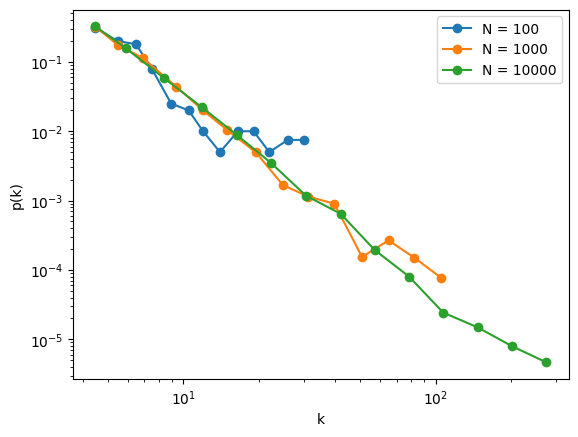

In [ ]:
def pick_targets(repeated_nodes, m):
    """Return a set of m distinct nodes, chosen with probability
    proportional to how often they appear in repeated_nodes."""
    targets = set()
    while len(targets) < m:
        t = random.choice(repeated_nodes)
        if t not in targets:
            targets.add(t)

    return targets



def grow_ba(N, m, seed):
  snapshots = {}
  random.seed(seed)

  # Initial K4
  #m = 4
  G = nx.complete_graph(4)

  repeated_nodes = []
  for i in range(G.number_of_nodes()):
    repeated_nodes.extend([i] * G.degree(i))


  for new in range(4, N):
    #pick targets
    pc = pick_targets(repeated_nodes, m)
    #updated repeated_nodes
    repeated_nodes.extend([new]*m)
    repeated_nodes.extend(pc)
    #snapshot check
    if (new +1) in {10**2, 10**3, N}:
      snapshots[new +1] = np.bincount(repeated_nodes)

  return snapshots

snapshots = grow_ba(10**4, 4, 0)


#TESTING TESTING
#print(len(repeated_nodes))
#print(snapshots.keys())
#print(snapshots[100].min(), len(snapshots[100]))
#a = grow_ba(10**4, 4, seed=0)
#b = grow_ba(10**4, 4, seed=0)
#c = grow_ba(10**4, 4, seed=1)
#print(np.array_equal(a[10**4], b[10**4]))  # expect True
#print(np.array_equal(a[10**4], c[10**4]))  # expect False

def log_binned(deg, num_bins = 15):
  k_min = deg.min()
  k_max = deg.max()
  edges = np.logspace(np.log10(k_min), np.log10(k_max+1), num_bins)
  edges = np.unique(np.round(edges))
  density, _ = np.histogram(deg, bins= edges, density=True)
  centers = np.sqrt((edges[:-1] * edges[1:]))
  mask = density > 0
  return centers[mask], density[mask]

for size, deg in snapshots.items():
    x, y = log_binned(deg)
    plt.loglog(x, y, 'o-', label=f'N = {size}')
    plt.xlabel('k')
    plt.ylabel('p(k)')
    plt.legend()

100 2.6933349609374995 4.0
1000 2.8738769531249995 6.0
10000 2.887225092492905 10.0


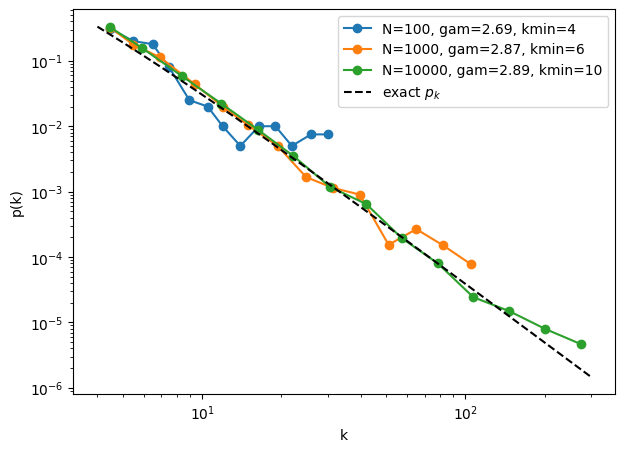

In [ ]:
m = 4
plt.figure(figsize=(7, 5))

for size, deg in snapshots.items():
    x, y = log_binned(deg)
    fit = powerlaw.Fit(deg, discrete=True, verbose=False)
    print(size, fit.alpha, fit.xmin)

    plt.loglog(x, y, 'o-',
               label=f'N={size}, gam={fit.alpha:.2f}, kmin={int(fit.xmin)}')

# exact degree distribution for comparison
k = np.arange(4, 300)
pk = 2*m*(m+1) / (k*(k+1)*(k+2))
plt.loglog(k, pk, 'k--', label='exact $p_k$')

plt.xlabel('k')
plt.ylabel('p(k)')
plt.legend()
plt.show()

In [ ]:
#GRow ensamble

degs = []
for seed in range(100):
  snaps = grow_ba(10**4, 4, seed)
  degs.append(snaps[10**4])


In [ ]:
# Estimator 1:

fits = [powerlaw.Fit(d, discrete=True, verbose=False) for d in degs]
gamma_pl = np.array([f.alpha for f in fits])


Help on package tailestim:

NAME
    tailestim

DESCRIPTION
    # SPDX-FileCopyrightText: 2025-present Minami Ueda
    #
    # SPDX-License-Identifier: MIT

PACKAGE CONTENTS
    __about__
    datasets
    estimators (package)

CLASSES
    abc.ABC(builtins.object)
        tailestim.estimators.base.BaseTailEstimator
            tailestim.estimators.hill.HillEstimator
            tailestim.estimators.kernel.KernelTypeEstimator
            tailestim.estimators.moments.MomentsEstimator
            tailestim.estimators.pickands.PickandsEstimator
            tailestim.estimators.smooth_hill.SmoothHillEstimator
    builtins.object
        tailestim.datasets.TailData
        tailestim.estimators.estimator_set.TailEstimatorSet

    class BaseTailEstimator(abc.ABC)
     |  BaseTailEstimator(
     |      bootstrap: bool = True,
     |      base_seed: Union[NoneType, numpy.random.bit_generator.SeedSequence, numpy.random.bit_generator.BitGenerator, numpy.random._generator.Generator, numpy.random.mtr

In [ ]:
results = {'hill': [], 'mom': [], 'ker': []}
for seed, d in enumerate(degs):
  for key, Est in [('hill', HillEstimator), ('mom', MomentsEstimator), ('ker', KernelTypeEstimator)]:
    est = Est(base_seed = seed)
    est.fit(d)
    results[key].append(est.get_result().gamma_)

/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1**2) / M2) < 1e-10)
/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:194: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1 * M2) / M3) < 1e-10)
/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:907: RuntimeWarning: invalid value encountered in divide
  xi_arr = gamma_pos - 1.0 + q2 / q1
/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:976: RuntimeWarning: invalid value encountered in divide
  xi_arr = gamma_pos - 1.0 + q2 / q1
/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:194: RuntimeWarning: divide by zero encountered in divide
  | (np.abs(1.0 - (M1 * M2) / M3) < 1e-10)
/usr/local/lib/python3.13/dist-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: divide by zero encountered in 

KeyboardInterrupt: 

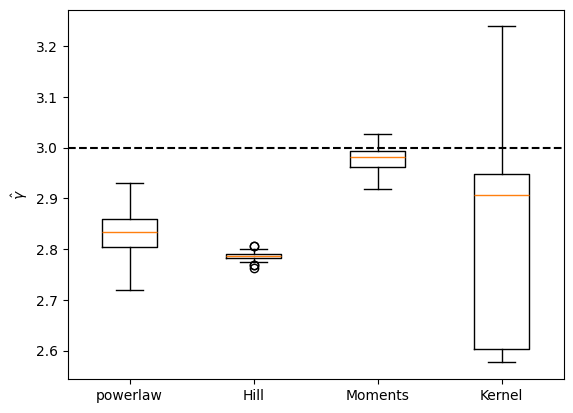

powerlaw  mean=2.832  std=0.043  failed=0
Hill      mean=2.787  std=0.007  failed=0
Moments   mean=2.978  std=0.022  failed=0
Kernel    mean=2.798  std=0.189  failed=0
favor power law (R>0, p<0.05): 0
favor lognormal (R<0, p<0.05): 4
inconclusive (p>=0.05):        96


In [ ]:
import warnings, logging
warnings.filterwarnings('ignore'); logging.disable(logging.WARNING)

# 1. ensemble of 100 networks (different seed each)
degs = [grow_ba(10**4, 4, seed)[10**4] for seed in range(100)]

# 2. powerlaw estimate (keep fit objects for the LR test)
fits = [powerlaw.Fit(d, discrete=True, verbose=False) for d in degs]
gamma = {'powerlaw': np.array([f.alpha for f in fits])}

# 3. tailestim estimators (gamma_ is already the exponent )
def run(Est, d, seed):
    try:
        est = Est(base_seed=seed, r_bootstrap=100)
        est.fit(d)
        return est.get_result().gamma_
    except Exception:
        return np.nan

for name, Est in [('Hill', HillEstimator), ('Moments', MomentsEstimator), ('Kernel', KernelTypeEstimator)]:
    gamma[name] = np.array([run(Est, d, s) for s, d in enumerate(degs)])

# 4. spread figure + mean/std
plt.boxplot([gamma[k][~np.isnan(gamma[k])] for k in gamma], labels=list(gamma))
plt.axhline(3, color='k', ls='--')
plt.ylabel(r'$\hat\gamma$'); plt.show()

for k, v in gamma.items():
    print(f'{k:9s} mean={np.nanmean(v):.3f}  std={np.nanstd(v):.3f}  failed={np.isnan(v).sum()}')

# 5. likelihood-ratio test: power law vs lognormal
R, p = np.array([f.distribution_compare('power_law', 'lognormal') for f in fits]).T
print('favor power law (R>0, p<0.05):', ((R > 0) & (p < 0.05)).sum())
print('favor lognormal (R<0, p<0.05):', ((R < 0) & (p < 0.05)).sum())
print('inconclusive (p>=0.05):       ', (p >= 0.05).sum())

Q2: seperate notebook cause of graph tool being stinkyyyyy


Q3:

In [ ]:
def powerlaw_degree_sequence(n, gamma, avg_k, k_max=None, seed=None):
    """
    Generates a power-law degree sequence with a tuned average degree.

    This function samples n integer degrees from a power-law distribution
    P(k) ~ k^-gamma within the range [k_min, k_max]. The lower bound k_min
    is numerically tuned (by evaluating candidate values) such that the
    theoretical expected mean of the truncated power law is as close as
    possible to the specified target 'avg_k'.

    To ensure suitability for constructing undirected networks (e.g., using
    the Configuration Model), the function guarantees that the sum of the
    generated degrees is an even integer. If the initial sample sum is odd,
    one randomly selected node's degree is adjusted by +/- 1.

    Parameters
    ----------
    n : int
        The number of nodes in the network (size of the degree sequence).
    gamma : float
        The power-law exponent (typically gamma > 1).
    avg_k : float
        The target average degree of the network.
    k_max : int, optional
        The maximum allowed degree (upper bound of the distribution).
        If None, it defaults to the "natural cutoff" defined as
        int(n ** (1 / (gamma - 1))), capped at n - 1.
    seed : int, RandomState, or Generator, optional
        Seed for the random number generator to ensure reproducibility.

    Returns
    -------
    deg : ndarray of shape (n,)
        An array of n integer degrees whose sum is even and whose average
        is tuned to be close to avg_k.
    """
    rng = np.random.default_rng(seed)
    if k_max is None:
        k_max = int(n ** (1 / (gamma - 1)))   # natural cutoff
        k_max = min(k_max, n - 1)

    def mean_for(kmin):
        ks = np.arange(kmin, k_max + 1)
        p = ks ** (-float(gamma)); p /= p.sum()
        return (ks * p).sum()

    # find integer k_min whose expected mean is closest to avg_k
    candidates = range(1, k_max)
    k_min = min(candidates, key=lambda m: abs(mean_for(m) - avg_k))

    ks = np.arange(k_min, k_max + 1)
    p = ks ** (-float(gamma)); p /= p.sum()
    deg = rng.choice(ks, size=n, p=p)

    # make the sum even (needed for the configuration model)
    if deg.sum() % 2 == 1:
        i = rng.integers(n)
        deg[i] += 1 if deg[i] < k_max else -1
    return deg

In [ ]:
def split_degrees(deg, mu, stochastic=False, seed=None):
    """
    Splits each node's total degree into internal (within-community) and
    external (between-community) degrees based on a mixing parameter.

    This function is typically used in the generation of community-structured
    benchmark graphs (such as LFR) to partition the total degree of each node
    according to the mixing parameter mu (representing the fraction of links
    connecting to other communities).

    Parameters
    ----------
    deg : array_like of int
        The total degrees (k_i) of the nodes in the network.
    mu : float
        The mixing parameter (0 <= mu <= 1), representing the target fraction
        of edges connecting each node to nodes outside its own community.
    stochastic : bool, default=False
        If True, the splitting is probabilistic: each stub of node i is assigned
        to be an external link independently with probability mu, modeled using
        a binomial distribution.
        If False, the splitting is deterministic: the external degree is
        calculated by multiplying the total degree by mu and rounding to the
        nearest integer.
    seed : int, RandomState, or Generator, optional
        Seed for the random number generator, used only if stochastic is True.

    Returns
    -------
    k_in : ndarray of int
        The internal degrees of the nodes, where k_in = deg - k_out.
    k_out : ndarray of int
        The external degrees of the nodes.
    """
    rng = np.random.default_rng(seed)
    deg = np.asarray(deg)
    if stochastic:
        # each stub is external with probability mu
        k_out = rng.binomial(deg, mu)
    else:
        k_out = np.round(deg * mu).astype(int)
    k_in = deg - k_out
    return k_in, k_out

In [ ]:

def try_lfr(n, tau1, tau2, mu, **kw):
    try:
        t = time.time()
        G = nx.LFR_benchmark_graph(n, tau1, tau2, mu, seed=0, max_iters=50, **kw)
        return True, time.time() - t
    except (nx.ExceededMaxIterations, nx.NetworkXError):
        return False, None

results = []
for n, tau1, tau2, mu, kavg, mincom in itertools.product(
        [250, 1000], [2.0, 2.5, 3.0], [1.1, 1.5, 2.0],
        [0.1, 0.3, 0.5, 0.7], [5, 15, 25], [10, 20, 50]):
    ok, t = try_lfr(n, tau1, tau2, mu, average_degree=kavg, min_community=mincom)
    results.append((n, tau1, tau2, mu, kavg, mincom, ok, t))

Q4 makeing zee package